<a href="https://colab.research.google.com/github/13rustam/Zhanakorgan_Agriculture/blob/main/12_PyStac_Unsupervised_Crop_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pystac-client

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 963.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 2.9 MB/s eta 0:00:00


In [2]:
from pystac_client import Client

In [3]:
catalog = Client.open(
    'https://earth-search.aws.element84.com/v1'
)

In [4]:
for collection in catalog.get_collections():
  print(collection.id)

sentinel-2-pre-c1-l2a
cop-dem-glo-30
naip
cop-dem-glo-90
landsat-c2-l2
sentinel-2-l2a
sentinel-2-l1c
sentinel-2-c1-l2a
sentinel-1-grd


In [5]:
roi = [67.311429, 43.551136, 67.386264, 43.59439]

In [8]:
search = catalog.search(
    collections = ['sentinel-2-c1-l2a'],
    bbox = roi,
    datetime = '2025'
)

In [9]:
items = search.item_collection()

In [10]:
len(items)

168

In [11]:
items[0].properties['proj:code']

'EPSG:32642'

In [12]:
items[0].assets.keys()

dict_keys(['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail'])

In [13]:
!pip install -q stackstac

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.3/64.3 kB 1.3 MB/s eta 0:00:00


In [14]:
import stackstac

In [23]:
stack_items = stackstac.stack(
    items,
    assets = ['red','nir', 'scl'],
    bounds_latlon = roi,
    epsg = 32642,
    resolution = 10
)

In [24]:
ds = (
    stack_items.to_dataset('band')
    .drop_dims('band')
    .reset_coords(drop = True)
    .drop_attrs()
)

In [25]:
mask = ds.scl.isin([3,8,9,10]).astype(int)
ds_mask = ds[['nir','red']].where(mask == 0)

In [26]:
red = ds_mask['red']
nir = ds_mask['nir']
ndvi = (nir - red) / (nir + red)

In [27]:
ndvi_monthly = ndvi.resample(time = 'M').mean('time')

/usr/local/lib/python3.13/dist-packages/xarray/groupers.py:530: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  self.index_grouper = pd.Grouper(


In [28]:
from dask.diagnostics import ProgressBar

In [29]:
import warnings
warnings.filterwarnings('ignore', category = RuntimeWarning)
import logging
logging.getLogger().setLevel(logging.ERROR)

In [30]:
with ProgressBar():
  ndvi_monthly = ndvi_monthly.compute()

[########################################] | 100% Completed | 99.72 s


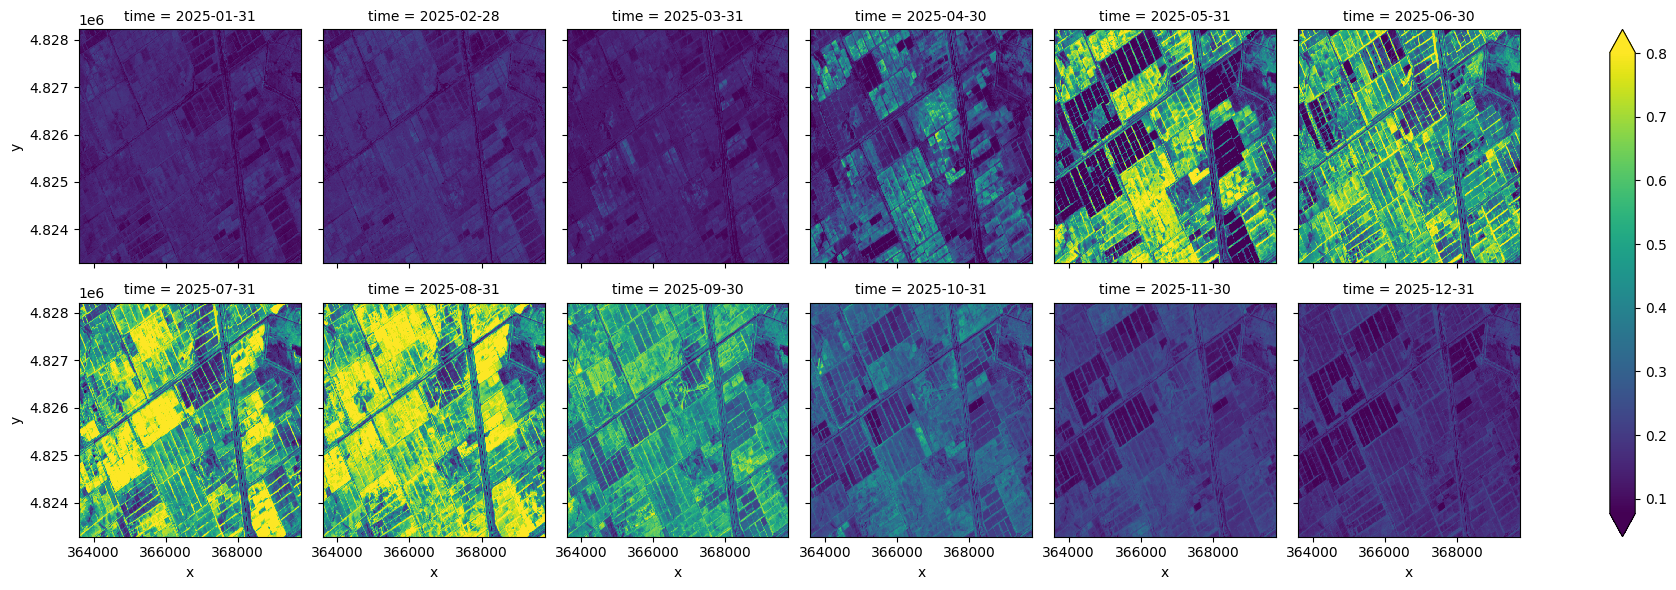

In [31]:
ndvi_monthly.plot(robust = True, col = 'time', col_wrap = 6)

In [32]:
from scipy.signal import savgol_filter

In [33]:
ndvi_monthly_vals = ndvi_monthly.values

In [34]:
ndvi_monthly

<xarray.DataArray (time: 12, y: 493, x: 615)> Size: 29MB
array([[[0.10979083, 0.10339726, 0.10597015, ..., 0.11247531,
         0.1173471 , 0.11209612],
        [0.11255764, 0.12034725, 0.11234298, ..., 0.12343587,
         0.14478535, 0.12050271],
        [0.10429392, 0.11470603, 0.10037315, ..., 0.11906069,
         0.13992362, 0.11604912],
        ...,
        [0.10920591, 0.14851308, 0.15886841, ..., 0.17340457,
         0.17763245, 0.14871497],
        [0.15229459, 0.15530362, 0.14380388, ..., 0.18144622,
         0.18708455, 0.18527513],
        [0.15958566, 0.14898882, 0.14560903, ..., 0.18221029,
         0.18150932, 0.16783731]],

       [[0.11455666, 0.11163955, 0.11193028, ..., 0.13677686,
         0.14292798, 0.15128258],
        [0.11505592, 0.12659012, 0.12554123, ..., 0.15193859,
         0.16699661, 0.15627717],
        [0.11434521, 0.11778223, 0.11059684, ..., 0.15222471,
         0.15624633, 0.14474965],
...
        [0.19109647, 0.21586656, 0.2246223 , ..., 0.2468492 ,
         0.24608711, 0.23486256],
        [0.22954282, 0.22828272, 0.23520978, ..., 0.26039894,
         0.25084881, 0.24986177],
        [0.23572449, 0.23403208, 0.22947782, ..., 0.26437665,
         0.24838033, 0.25944309]],

       [[0.21512668, 0.19419255, 0.18970481, ..., 0.11478323,
         0.11760987, 0.10943096],
        [0.18267675, 0.17600957, 0.17745271, ..., 0.1176159 ,
         0.12015294, 0.12128875],
        [0.16988362, 0.1682165 , 0.16540197, ..., 0.12539785,
         0.12777135, 0.12353335],
        ...,
        [0.17033722, 0.20037605, 0.20799958, ..., 0.17017214,
         0.16549804, 0.16506307],
        [0.21324304, 0.21792847, 0.21981865, ..., 0.18307798,
         0.17200742, 0.1723696 ],
        [0.2309256 , 0.21568757, 0.19983294, ..., 0.19062868,
         0.17910482, 0.18159813]]])
Coordinates:
  * time     (time) datetime64[ns] 96B 2025-01-31 2025-02-28 ... 2025-12-31
  * y        (y) float64 4kB 4.828e+06 4.828e+06 ... 4.823e+06 4.823e+06
  * x        (x) float64 5kB 3.636e+05 3.636e+05 ... 3.697e+05 3.697e+05

In [35]:
ndvi_monthly_vals.shape

(12, 493, 615)

In [36]:
help(savgol_filter)

Help on function savgol_filter in module scipy.signal._savitzky_golay:

savgol_filter(
    x,
    window_length,
    polyorder,
    deriv=0,
    delta=1.0,
    axis=-1,
    mode='interp',
    cval=0.0
)
    Apply a Savitzky-Golay filter to an array.

    This is a 1-D filter. If `x`  has dimension greater than 1, `axis`
    determines the axis along which the filter is applied.

    Parameters
    ----------
    x : array_like
        The data to be filtered. If `x` is not a single or double precision
        floating point array, it will be converted to type ``numpy.float64``
        before filtering.
    window_length : int
        The length of the filter window (i.e., the number of coefficients).
        If `mode` is 'interp', `window_length` must be less than or equal
        to the size of `x`.
    polyorder : int
        The order of the polynomial used to fit the samples.
        `polyorder` must be less than `window_length`.
    deriv : int, optional
        The order of the d

In [37]:
ndvi_filter = savgol_filter(
    ndvi_monthly_vals,
    window_length = 5,
    polyorder = 2,
    axis =  0
)

In [38]:
import xarray as xr

In [39]:
ndvi_smooth = xr.DataArray(
    ndvi_filter,
    dims = ndvi_monthly.dims,
    coords =ndvi_monthly.coords
)

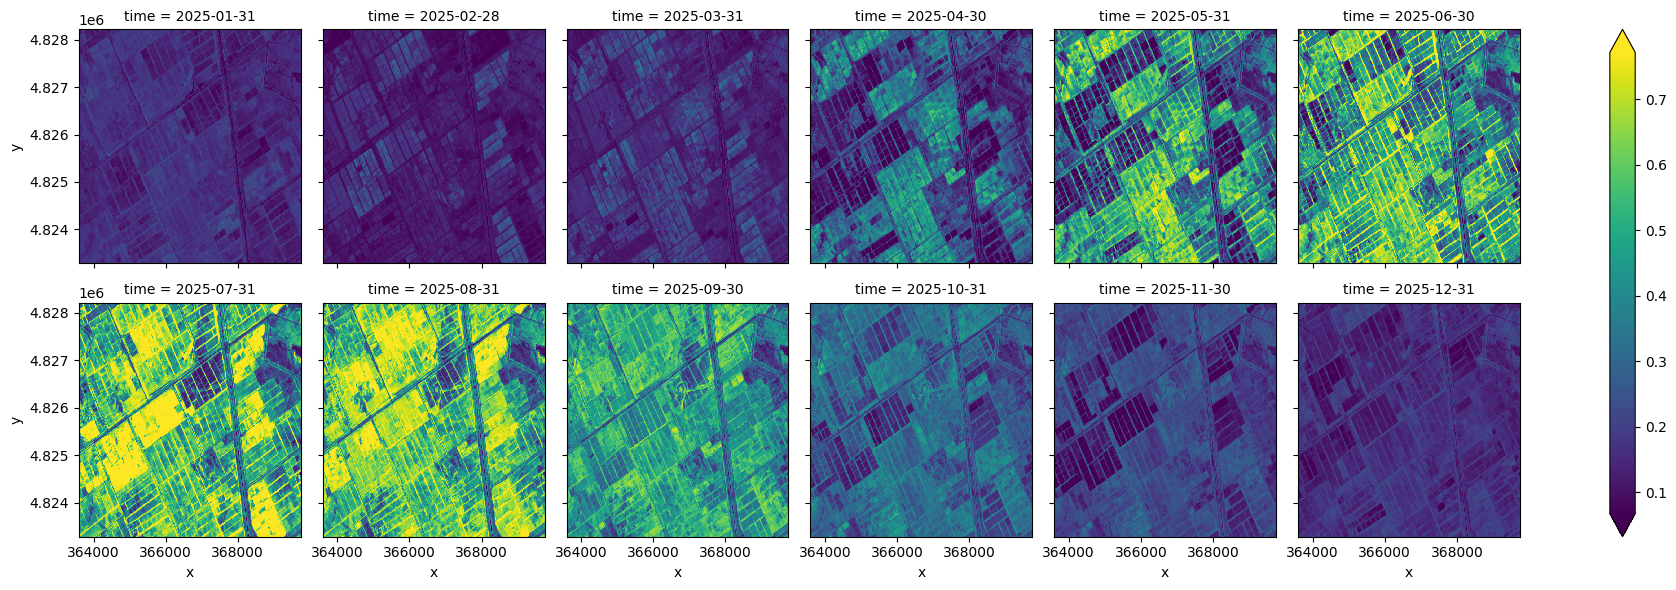

In [40]:
ndvi_smooth.plot(robust = True, col = 'time', col_wrap = 6)

In [41]:
!pip install -q tslearn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 401.7/401.7 kB 4.2 MB/s eta 0:00:00


In [42]:
from tslearn.clustering import TimeSeriesKMeans

In [43]:
ndvi_stack = ndvi_smooth.stack(pixel = ['y','x']).transpose('pixel', 'time')

In [44]:
valid = ndvi_stack.notnull().all('time')

In [45]:
model = TimeSeriesKMeans(
    n_clusters = 4,
    random_state =42,
    metric = 'euclidean',
    max_iter =10
)

In [46]:
labels = model.fit_predict(ndvi_stack[valid].values)

In [47]:
classified = xr.DataArray(
    labels,
    dims = 'pixel',
    coords = {'pixel': ndvi_stack[valid].pixel}
).unstack('pixel')

In [48]:
import numpy as np

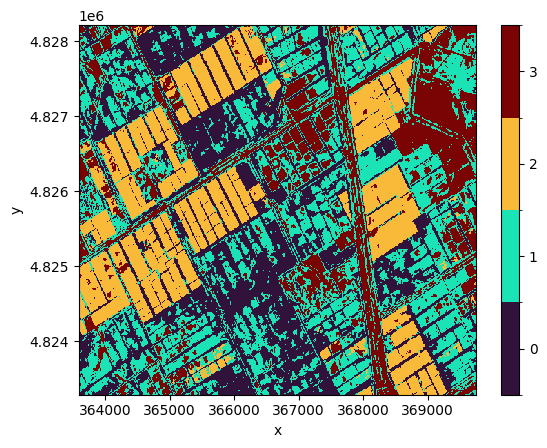

In [49]:
classified.plot(cmap = 'turbo',levels =  np.arange(-0.5, 4, 1),
                cbar_kwargs = {'ticks': range(4)})

In [50]:
import pandas as pd

In [51]:
ndvi_stack.shape

(303195, 12)

In [52]:
df = pd.DataFrame({'date': ndvi_stack.time.values})

for i in np.unique(classified.values):
  ndvi_mean = ndvi_stack[valid][labels == i].mean(axis = 0)
  df[f'cluster_{i}'] = ndvi_mean

In [53]:
df

,date,cluster_0,cluster_1,cluster_2,cluster_3
0,2025-01-31,0.181603,0.153310,0.139038,0.129162
1,2025-02-28,0.114236,0.110451,0.181567,0.113687
2,2025-03-31,0.167220,0.146184,0.180548,0.124775
3,2025-04-30,0.355855,0.269683,0.103472,0.160767
4,2025-05-31,0.574734,0.411258,0.143725,0.218063
5,2025-06-30,0.666464,0.458707,0.367192,0.247223
6,2025-07-31,0.666050,0.466132,0.709541,0.268288
7,2025-08-31,0.664252,0.499971,0.703163,0.298033
8,2025-09-30,0.544721,0.447500,0.452026,0.286158
9,2025-10-31,0.351043,0.308983,0.204410,0.225916


In [54]:
import matplotlib.pyplot as plt

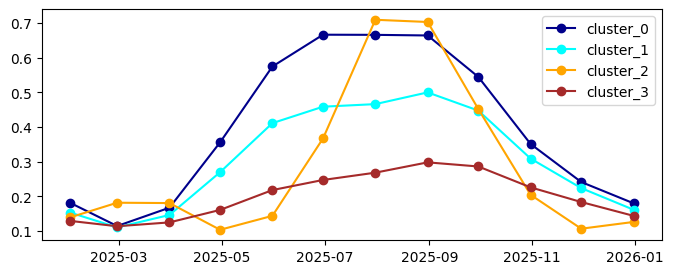

In [55]:
fig, ax = plt.subplots(figsize = (8, 3))

ax.plot(df.date, df.cluster_0, marker = 'o', label = 'cluster_0', color = 'darkblue')
ax.plot(df.date, df.cluster_1, marker ='o', color = 'cyan', label = 'cluster_1')
ax.plot(df.date, df.cluster_2, marker ='o', color = 'orange', label = 'cluster_2')
ax.plot(df.date, df.cluster_3, marker = 'o', color = 'brown', label = 'cluster_3')

ax.legend()